<a href="https://colab.research.google.com/github/wUssopp/Eksploracja-Danych/blob/main/Lab2_pandas_wizualizacja_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorium 2: Wstęp do pandas i wizualizacja danych

**Plan zajęć**
- **Część A – pandas** (ok. 50 min): tworzenie `DataFrame`, inspekcja, sortowanie, wybieranie kolumn, filtrowanie, nowe kolumny → zadania 1–6 i zadanie zaawansowane.
- **Część B – wizualizacja** (ok. 40 min): wykres słupkowy, punktowy i liniowy w trzech bibliotekach (matplotlib, pandas, seaborn), format szeroki i długi (`melt`) → zadania 7–10.

Notebook umieść w swoim repozytorium na GitHubie przed kolejnymi zajęciami.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ustawienia dla polskich znaków i czytelności wykresów
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams.update({'font.size': 12})
sns.set_style("whitegrid")

# **Część A: Wstęp do pandas**

`Pandas` to biblioteka w Pythonie, która umożliwia łatwe i efektywne manipulowanie oraz analizowanie danych.

Jest szczególnie przydatna do pracy z danymi tabelarycznymi, podobnymi do tych w arkuszach kalkulacyjnych.

## CZĘŚĆ 1: Tworzenie DataFrame z polskimi danymi

In [ ]:
# Przykład 1: Dane o polskich miastach
data_miasta = {
    'Miasto': ['Warszawa', 'Kraków', 'Łódź', 'Wrocław', 'Poznań', 'Gdańsk', 'Szczecin'],
    'Województwo': ['mazowieckie', 'małopolskie', 'łódzkie', 'dolnośląskie',
                    'wielkopolskie', 'pomorskie', 'zachodniopomorskie'],
    'Populacja': [1863056, 779966, 672185, 643782, 532048, 470907, 395513],
    'Powierzchnia_km2': [517, 327, 293, 293, 262, 262, 301],
    'Rok_nadania_praw': [1413, 1257, 1423, 1242, 1253, 1263, 1243]
}

miasta = pd.DataFrame(data_miasta)
print(miasta)

     Miasto         Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa         mazowieckie    1863056               517              1413
1    Kraków         małopolskie     779966               327              1257
2      Łódź             łódzkie     672185               293              1423
3   Wrocław        dolnośląskie     643782               293              1242
4    Poznań       wielkopolskie     532048               262              1253
5    Gdańsk           pomorskie     470907               262              1263
6  Szczecin  zachodniopomorskie     395513               301              1243


## CZĘŚĆ 2: PODSTAWOWE METODY INSPEKCJI DANYCH

In [ ]:
print(">>> .head() - Pierwsze 5 wierszy (lub inna liczba)")
print(miasta.head(3))

>>> .head() - Pierwsze 5 wierszy (lub inna liczba)
     Miasto  Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa  mazowieckie    1863056               517              1413
1    Kraków  małopolskie     779966               327              1257
2      Łódź      łódzkie     672185               293              1423


In [ ]:
print(">>> .info() - Informacje o strukturze danych")
miasta.info()

>>> .info() - Informacje o strukturze danych
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Miasto            7 non-null      object
 1   Województwo       7 non-null      object
 2   Populacja         7 non-null      int64 
 3   Powierzchnia_km2  7 non-null      int64 
 4   Rok_nadania_praw  7 non-null      int64 
dtypes: int64(3), object(2)
memory usage: 412.0+ bytes


In [ ]:
print(">>> .shape - Wymiary DataFrame (wiersze, kolumny)")
print(f"Nasz DataFrame ma: {miasta.shape[0]} wierszy i {miasta.shape[1]} kolumn")

>>> .shape - Wymiary DataFrame (wiersze, kolumny)
Nasz DataFrame ma: 7 wierszy i 5 kolumn


In [ ]:
print(">>> .describe() - Statystyki opisowe dla kolumn numerycznych")
print(miasta.describe())

>>> .describe() - Statystyki opisowe dla kolumn numerycznych
          Populacja  Powierzchnia_km2  Rok_nadania_praw
count  7.000000e+00          7.000000          7.000000
mean   7.653510e+05        322.142857       1299.142857
std    5.010882e+05         88.856492         81.581102
min    3.955130e+05        262.000000       1242.000000
25%    5.014775e+05        277.500000       1248.000000
50%    6.437820e+05        293.000000       1257.000000
75%    7.260755e+05        314.000000       1338.000000
max    1.863056e+06        517.000000       1423.000000


In [ ]:
print(">>> .columns - Nazwy kolumn")
print(miasta.columns.tolist())

>>> .columns - Nazwy kolumn
['Miasto', 'Województwo', 'Populacja', 'Powierzchnia_km2', 'Rok_nadania_praw']


In [ ]:
print(">>> .index - Indeks wierszy")
print(miasta.index)

>>> .index - Indeks wierszy
RangeIndex(start=0, stop=7, step=1)


## CZĘŚĆ 3: SORTOWANIE DANYCH

In [ ]:
print("1. Sortowanie rosnąco po populacji:")
print(miasta.sort_values("Populacja").head())

1. Sortowanie rosnąco po populacji:
     Miasto         Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
6  Szczecin  zachodniopomorskie     395513               301              1243
5    Gdańsk           pomorskie     470907               262              1263
4    Poznań       wielkopolskie     532048               262              1253
3   Wrocław        dolnośląskie     643782               293              1242
2      Łódź             łódzkie     672185               293              1423


In [ ]:
print("2. Sortowanie malejąco po populacji:")
print(miasta.sort_values("Populacja", ascending=False).head())

2. Sortowanie malejąco po populacji:
     Miasto    Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa    mazowieckie    1863056               517              1413
1    Kraków    małopolskie     779966               327              1257
2      Łódź        łódzkie     672185               293              1423
3   Wrocław   dolnośląskie     643782               293              1242
4    Poznań  wielkopolskie     532048               262              1253


## CZĘŚĆ 4: WYBIERANIE KOLUMN

In [ ]:
print("1. Jedna kolumna (zwraca Series):")
print(miasta["Miasto"])
print(f"\nTyp: {type(miasta['Miasto'])}")

1. Jedna kolumna (zwraca Series):
0    Warszawa
1      Kraków
2        Łódź
3     Wrocław
4      Poznań
5      Gdańsk
6    Szczecin
Name: Miasto, dtype: object

Typ: <class 'pandas.core.series.Series'>


In [ ]:
print("2. Wiele kolumn (zwraca DataFrame):")
print(miasta[["Miasto", "Populacja"]])

2. Wiele kolumn (zwraca DataFrame):
     Miasto  Populacja
0  Warszawa    1863056
1    Kraków     779966
2      Łódź     672185
3   Wrocław     643782
4    Poznań     532048
5    Gdańsk     470907
6  Szczecin     395513


In [ ]:
print("3. Używanie zmiennej z listą kolumn:")
kolumny_do_wyswietlenia = ["Miasto",
                           "Województwo",
                           "Populacja"]
print(miasta[kolumny_do_wyswietlenia])

3. Używanie zmiennej z listą kolumn:
     Miasto         Województwo  Populacja
0  Warszawa         mazowieckie    1863056
1    Kraków         małopolskie     779966
2      Łódź             łódzkie     672185
3   Wrocław        dolnośląskie     643782
4    Poznań       wielkopolskie     532048
5    Gdańsk           pomorskie     470907
6  Szczecin  zachodniopomorskie     395513


## CZĘŚĆ 5: FILTROWANIE WIERSZY

In [ ]:
print("1. Miasta z populacją powyżej 600 000:")
print(miasta[miasta["Populacja"] > 600000])

1. Miasta z populacją powyżej 600 000:
     Miasto   Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa   mazowieckie    1863056               517              1413
1    Kraków   małopolskie     779966               327              1257
2      Łódź       łódzkie     672185               293              1423
3   Wrocław  dolnośląskie     643782               293              1242


In [ ]:
print("2. Miasta z województwa mazowieckiego:")
print(miasta[miasta["Województwo"] == "mazowieckie"])

2. Miasta z województwa mazowieckiego:
     Miasto  Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa  mazowieckie    1863056               517              1413


In [ ]:
print("3. Miasta z prawami miejskimi przed 1300 rokiem:")
print(miasta[miasta["Rok_nadania_praw"] < 1300])

3. Miasta z prawami miejskimi przed 1300 rokiem:
     Miasto         Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
1    Kraków         małopolskie     779966               327              1257
3   Wrocław        dolnośląskie     643782               293              1242
4    Poznań       wielkopolskie     532048               262              1253
5    Gdańsk           pomorskie     470907               262              1263
6  Szczecin  zachodniopomorskie     395513               301              1243


In [ ]:
print("4. Złożone warunki z operatorem AND (&):")
print("   Miasta powyżej 500k ludności I powierzchnia powyżej 280 km²")
duze_miasta = miasta[(miasta["Populacja"] > 500000) &
                     (miasta["Powierzchnia_km2"] > 280)]
print(duze_miasta)

4. Złożone warunki z operatorem AND (&):
   Miasta powyżej 500k ludności I powierzchnia powyżej 280 km²
     Miasto   Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa   mazowieckie    1863056               517              1413
1    Kraków   małopolskie     779966               327              1257
2      Łódź       łódzkie     672185               293              1423
3   Wrocław  dolnośląskie     643782               293              1242


In [ ]:
print("5. Złożone warunki z operatorem OR (|):")
print("   Miasta z Warszawy LUB Krakowa")
stolice = miasta[(miasta["Miasto"] == "Warszawa") |
                 (miasta["Miasto"] == "Kraków")]
print(stolice)

5. Złożone warunki z operatorem OR (|):
   Miasta z Warszawy LUB Krakowa
     Miasto  Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa  mazowieckie    1863056               517              1413
1    Kraków  małopolskie     779966               327              1257


In [ ]:
print("6. Używanie .isin() dla wielu wartości:")
wybrane_miasta = ["Warszawa", "Kraków", "Wrocław"]
print(miasta[miasta["Miasto"].isin(wybrane_miasta)])

6. Używanie .isin() dla wielu wartości:
     Miasto   Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa   mazowieckie    1863056               517              1413
1    Kraków   małopolskie     779966               327              1257
3   Wrocław  dolnośląskie     643782               293              1242


## CZĘŚĆ 6: DODAWANIE NOWYCH KOLUMN

In [ ]:
print("1. Obliczanie gęstości zaludnienia:")
miasta["Gęstość_na_km2"] = miasta["Populacja"] / miasta["Powierzchnia_km2"]
print(miasta[["Miasto", "Populacja", "Powierzchnia_km2", "Gęstość_na_km2"]])

1. Obliczanie gęstości zaludnienia:
     Miasto  Populacja  Powierzchnia_km2  Gęstość_na_km2
0  Warszawa    1863056               517     3603.589942
1    Kraków     779966               327     2385.217125
2      Łódź     672185               293     2294.146758
3   Wrocław     643782               293     2197.208191
4    Poznań     532048               262     2030.717557
5    Gdańsk     470907               262     1797.354962
6  Szczecin     395513               301     1313.996678


In [ ]:
print("2. Kategoryzacja miast według wielkości:")
def kategoryzuj_miasto(populacja):
    if populacja > 1000000:
        return "Bardzo duże"
    elif populacja > 500000:
        return "Duże"
    else:
        return "Średnie"

miasta["Kategoria"] = miasta["Populacja"].apply(kategoryzuj_miasto)
print(miasta[["Miasto", "Populacja", "Kategoria"]])

2. Kategoryzacja miast według wielkości:
     Miasto  Populacja    Kategoria
0  Warszawa    1863056  Bardzo duże
1    Kraków     779966         Duże
2      Łódź     672185         Duże
3   Wrocław     643782         Duże
4    Poznań     532048         Duże
5    Gdańsk     470907      Średnie
6  Szczecin     395513      Średnie


# **Zadania – część A**

In [ ]:
# Dataset do zadań
temperatura = pd.DataFrame({
    'Miasto': ['Warszawa', 'Kraków', 'Gdańsk', 'Wrocław', 'Poznań', 'Łódź'],
    'Styczeń': [-2, -1, 0, -1, -2, -3],
    'Kwiecień': [9, 10, 8, 11, 10, 9],
    'Lipiec': [19, 20, 17, 21, 19, 20],
    'Październik': [9, 9, 10, 10, 9, 8]
})

print("Dataset 'temperatura' - średnie temperatury w polskich miastach:")
print(temperatura)

Dataset 'temperatura' - średnie temperatury w polskich miastach:
     Miasto  Styczeń  Kwiecień  Lipiec  Październik
0  Warszawa       -2         9      19            9
1    Kraków       -1        10      20            9
2    Gdańsk        0         8      17           10
3   Wrocław       -1        11      21           10
4    Poznań       -2        10      19            9
5      Łódź       -3         9      20            8


## **Zadanie 1: podstawowa inspekcja**

Używając DataFrame `temperatura`, wykonaj następujące operacje:

a) Wyświetl pierwsze 3 wiersze

b) Wyświetl informacje o typach danych (.info())

c) Wyświetl kształt DataFrame (.shape)

d) Wyświetl tylko nazwy kolumn (.columns)

In [ ]:
print(temperatura.head(3))

temperatura.info()

print(temperatura.shape)

print(temperatura.columns.tolist())

     Miasto  Styczeń  Kwiecień  Lipiec  Październik
0  Warszawa       -2         9      19            9
1    Kraków       -1        10      20            9
2    Gdańsk        0         8      17           10
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Miasto       6 non-null      object
 1   Styczeń      6 non-null      int64 
 2   Kwiecień     6 non-null      int64 
 3   Lipiec       6 non-null      int64 
 4   Październik  6 non-null      int64 
dtypes: int64(4), object(1)
memory usage: 372.0+ bytes
(6, 5)
['Miasto', 'Styczeń', 'Kwiecień', 'Lipiec', 'Październik']


## **Zadanie 2: sortowanie**

a) Posortuj miasta według temperatury w lipcu (rosnąco)

b) Posortuj miasta według temperatury w styczniu (malejąco)

c) Posortuj miasta według temperatury w lipcu malejąco,

d) Posortuj miasta według temperatury w kwietnia rosnąco

In [ ]:
print(temperatura.sort_values('Lipiec')[['Miasto', 'Lipiec']])

print(temperatura.sort_values('Styczeń', ascending=False)[['Miasto', 'Styczeń']])

print(temperatura.sort_values('Lipiec', ascending=False)[['Miasto', 'Lipiec']])

print(temperatura.sort_values('Kwiecień')[['Miasto', 'Kwiecień']])

     Miasto  Lipiec
2    Gdańsk      17
0  Warszawa      19
4    Poznań      19
1    Kraków      20
5      Łódź      20
3   Wrocław      21
     Miasto  Styczeń
2    Gdańsk        0
1    Kraków       -1
3   Wrocław       -1
0  Warszawa       -2
4    Poznań       -2
5      Łódź       -3
     Miasto  Lipiec
3   Wrocław      21
1    Kraków      20
5      Łódź      20
0  Warszawa      19
4    Poznań      19
2    Gdańsk      17
     Miasto  Kwiecień
2    Gdańsk         8
0  Warszawa         9
5      Łódź         9
1    Kraków        10
4    Poznań        10
3   Wrocław        11


## **Zadanie 3: Wybieranie kolumn**

a) Wybierz tylko kolumnę 'Miasto' (wynik: Series)

b) Wybierz kolumny 'Miasto' i 'Lipiec' (wynik: DataFrame)

c) Wybierz kolumny 'Miasto', 'Styczeń' i 'Lipiec', używając zmiennej z listą nazw kolumn

In [ ]:
print(temperatura['Miasto'])

print(temperatura[['Miasto', 'Lipiec']])

wybrane_kolumny = ['Miasto', 'Styczeń', 'Lipiec']
print(temperatura[wybrane_kolumny])

0    Warszawa
1      Kraków
2      Gdańsk
3     Wrocław
4      Poznań
5        Łódź
Name: Miasto, dtype: object
     Miasto  Lipiec
0  Warszawa      19
1    Kraków      20
2    Gdańsk      17
3   Wrocław      21
4    Poznań      19
5      Łódź      20
     Miasto  Styczeń  Lipiec
0  Warszawa       -2      19
1    Kraków       -1      20
2    Gdańsk        0      17
3   Wrocław       -1      21
4    Poznań       -2      19
5      Łódź       -3      20


## **Zadanie 4: Filtrowanie**
a) Znajdź miasta, gdzie temperatura w lipcu jest większa niż 19 stopni

b) Znajdź miasta, gdzie temperatura w styczniu jest większa lub równa -1

c) Znajdź miasta, gdzie temperatura w kwietniu wynosi dokładnie 10 stopni

d) Znajdź miasta, gdzie temperatura w lipcu jest 20 LUB temperatura w styczniu jest -1

In [ ]:
print(temperatura[['Miasto', 'Lipiec']][temperatura['Lipiec'] > 19])

print(temperatura[['Miasto', 'Styczeń']][temperatura['Styczeń'] >= -1])

print(temperatura[['Miasto', 'Kwiecień']][temperatura['Kwiecień'] == 10])

print(temperatura[['Miasto', 'Styczeń', 'Lipiec']][(temperatura['Lipiec'] == 20) | (temperatura['Styczeń'] == -1)])

    Miasto  Lipiec
1   Kraków      20
3  Wrocław      21
5     Łódź      20
    Miasto  Styczeń
1   Kraków       -1
2   Gdańsk        0
3  Wrocław       -1
   Miasto  Kwiecień
1  Kraków        10
4  Poznań        10
    Miasto  Styczeń  Lipiec
1   Kraków       -1      20
3  Wrocław       -1      21
5     Łódź       -3      20


## **Zadanie 5: Złożone filtrowanie**
a) Znajdź miasta, gdzie temperatura w lipcu > 18 ORAZ w styczniu >= -2

b) Znajdź miasta: 'Warszawa', 'Kraków', 'Gdańsk'

c) Znajdź miasta, gdzie temperatura w lipcu jest między 18 a 20 stopni (włącznie)

In [ ]:
print(temperatura[(temperatura['Lipiec'] > 18) & (temperatura['Styczeń'] >= -2)][['Miasto', 'Styczeń', 'Lipiec']])

print(temperatura[temperatura['Miasto'].isin(['Warszawa', 'Kraków', 'Gdańsk'])])

print(temperatura[temperatura['Lipiec'].between(18, 20)][['Miasto', 'Lipiec']])

     Miasto  Styczeń  Lipiec
0  Warszawa       -2      19
1    Kraków       -1      20
3   Wrocław       -1      21
4    Poznań       -2      19
     Miasto  Styczeń  Kwiecień  Lipiec  Październik
0  Warszawa       -2         9      19            9
1    Kraków       -1        10      20            9
2    Gdańsk        0         8      17           10
     Miasto  Lipiec
0  Warszawa      19
1    Kraków      20
4    Poznań      19
5      Łódź      20


## **Zadanie 6: Dodawanie nowych kolumn**
a) Dodaj kolumnę 'Średnia_roczna' - średnia z wszystkich miesięcy

b) Dodaj kolumnę 'Amplituda' - różnica między lipcem a styczniem

c) Dodaj kolumnę 'Ciepłe_miasto' (True jeśli średnia roczna > 11, False w przeciwnym razie)

In [ ]:
temperatura['Średnia_roczna'] = temperatura[['Styczeń', 'Kwiecień', 'Lipiec', 'Październik']].mean(axis=1)

temperatura['Amplituda'] = temperatura['Lipiec'] - temperatura['Styczeń']

temperatura['Ciepłe_miasto'] = temperatura['Średnia_roczna'] > 11

print(temperatura[['Miasto', 'Średnia_roczna', 'Amplituda', 'Ciepłe_miasto']])

     Miasto  Średnia_roczna  Amplituda  Ciepłe_miasto
0  Warszawa            8.75         21          False
1    Kraków            9.50         21          False
2    Gdańsk            8.75         17          False
3   Wrocław           10.25         22          False
4    Poznań            9.00         21          False
5      Łódź            8.50         23          False


## **Zadanie zaawansowane**

Uruchom komórkę z danymi poniżej, a następnie:

a) Dodaj kolumnę `'Średnia'` z wyników z trzech przedmiotów

b) Dodaj kolumnę `'Status'` – `'Zaliczony'` jeśli średnia >= 85, `'Niezaliczony'` w przeciwnym razie

c) Dla każdego kierunku znajdź studenta z najwyższą średnią:
   - przefiltruj po kierunku,
   - posortuj według średniej malejąco,
   - weź pierwszy wiersz,
   - wykonaj dla każdego z 3 kierunków.

d) Znajdź wszystkich studentów informatyki, którzy mają średnią >= 85
   i wynik z informatyki >= 90, posortowanych według średniej malejąco

In [ ]:
wyniki_egzaminy = pd.DataFrame({
    'Student': ['Anna', 'Bartek', 'Celina', 'Damian', 'Ewa', 'Filip', 'Gabriela', 'Hubert'],
    'Matematyka': [85, 92, 78, 88, 95, 72, 89, 81],
    'Fizyka': [78, 88, 82, 75, 91, 68, 85, 79],
    'Informatyka': [92, 85, 88, 90, 89, 95, 82, 87],
    'Kierunek': ['Informatyka', 'Fizyka', 'Matematyka', 'Informatyka',
                 'Matematyka', 'Informatyka', 'Fizyka', 'Matematyka']
})

In [ ]:
import numpy as np

wyniki_egzaminy['Średnia'] = wyniki_egzaminy[['Matematyka', 'Fizyka', 'Informatyka']].mean(axis=1)

wyniki_egzaminy['Status'] = np.where(wyniki_egzaminy['Średnia'] >= 85, 'Zaliczony', 'Niezaliczony')

kierunki = wyniki_egzaminy['Kierunek'].unique()
for kierunek in kierunki:
    najlepszy = wyniki_egzaminy[wyniki_egzaminy['Kierunek'] == kierunek].sort_values('Średnia', ascending=False).iloc[0]
    print(f"{kierunek} - Najlepszy wynik: {najlepszy['Student']} (Średnia: {najlepszy['Średnia']:.2f})")

print("\n")

wybitni_informatycy = wyniki_egzaminy[
    (wyniki_egzaminy['Kierunek'] == 'Informatyka') &
    (wyniki_egzaminy['Średnia'] >= 85) &
    (wyniki_egzaminy['Informatyka'] >= 90)
].sort_values('Średnia', ascending=False)

print(wybitni_informatycy[['Student', 'Kierunek', 'Średnia', 'Informatyka']])

Informatyka - Najlepszy wynik: Anna (Średnia: 85.00)
Fizyka - Najlepszy wynik: Bartek (Średnia: 88.33)
Matematyka - Najlepszy wynik: Ewa (Średnia: 91.67)


  Student     Kierunek  Średnia  Informatyka
0    Anna  Informatyka     85.0           92


# **Część B: Wizualizacja danych**

Ten sam wykres można narysować na trzy sposoby:

| Biblioteka | Zalety | Wady | Kiedy używać |
|------------|--------|------|--------------|
| **matplotlib** | pełna kontrola, elastyczność | wymaga więcej kodu | gdy potrzebna jest precyzyjna kontrola |
| **pandas** (`.plot`) | szybkie, wygodne dla `DataFrame` | ograniczone opcje stylizacji | szybka eksploracja danych |
| **seaborn** | estetyczne wykresy statystyczne, `hue` | mniejsza kontrola, wymaga *formatu długiego* | analiza statystyczna, raporty |

Pracujemy dalej na DataFrame `miasta` z części A (z kolumnami `Gęstość_na_km2` i `Kategoria`) oraz `temperatura` z zadań. Przed częścią B uruchom wszystkie komórki części A.

## CZĘŚĆ 7: WYKRES SŁUPKOWY – porównanie kategorii

**Pytanie:** które miasto jest największe i jak duże są różnice?

In [ ]:
# Populacja w tysiącach – czytelniejsze osie niż 1e6
miasta["Populacja_tys"] = miasta["Populacja"] / 1000

# Sortujemy, żeby słupki ułożyły się od największego do najmniejszego
miasta_sort = miasta.sort_values("Populacja", ascending=False)

### Metoda 1: matplotlib

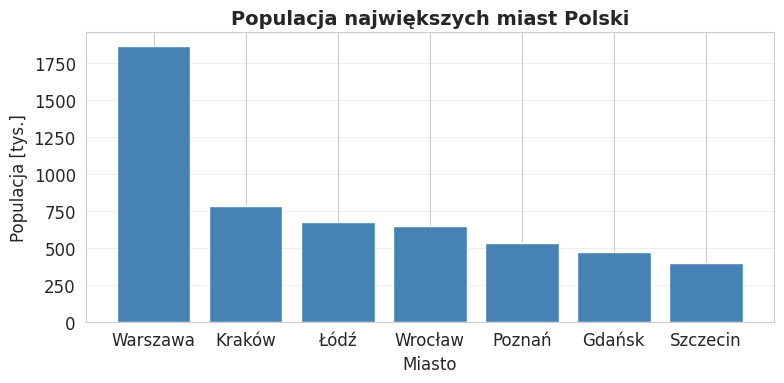

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(miasta_sort["Miasto"], miasta_sort["Populacja_tys"], color="steelblue")

ax.set_title("Populacja największych miast Polski", fontsize=14, fontweight="bold")
ax.set_xlabel("Miasto")
ax.set_ylabel("Populacja [tys.]")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Metoda 2: pandas

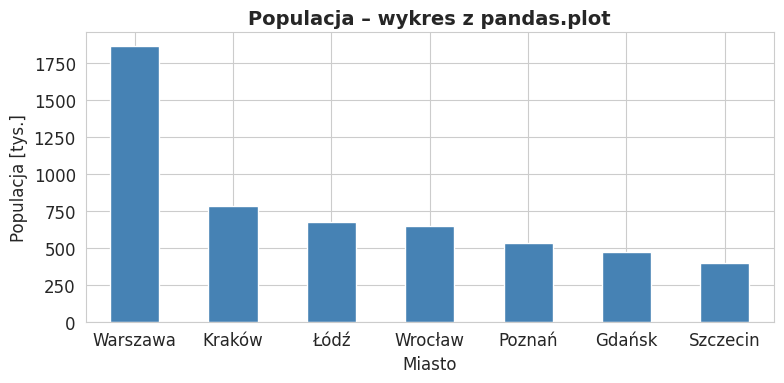

In [ ]:
ax = miasta_sort.plot.bar(x="Miasto", y="Populacja_tys", color="steelblue",
                         legend=False, rot=0, figsize=(8, 4))

ax.set_title("Populacja – wykres z pandas.plot", fontsize=14, fontweight="bold")
ax.set_ylabel("Populacja [tys.]")
plt.tight_layout()
plt.show()

### Metoda 3: seaborn

Seaborn pozwala jednym parametrem pokolorować słupki według innej kolumny (`hue`) – tu według kategorii z części A.

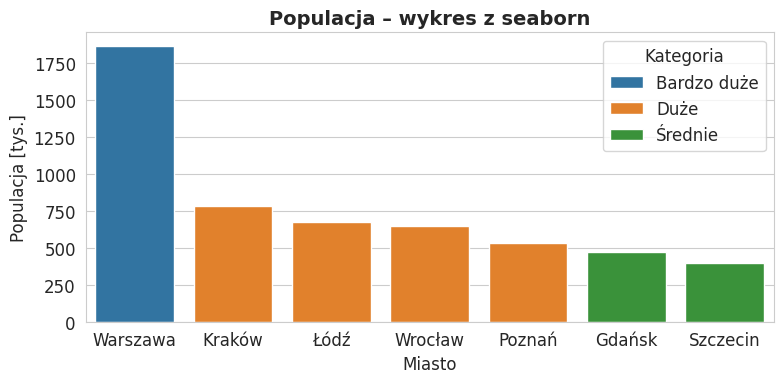

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(data=miasta_sort, x="Miasto", y="Populacja_tys", hue="Kategoria")

plt.title("Populacja – wykres z seaborn", fontsize=14, fontweight="bold")
plt.ylabel("Populacja [tys.]")
plt.tight_layout()
plt.show()

> **Uwaga:** oś Y na wykresie słupkowym zawsze zaczynamy od zera. Ucięta oś (np. od 300 tys.) sprawiłaby, że różnice wyglądałyby na wielokrotnie większe, niż są.

## CZĘŚĆ 8: WYKRES PUNKTOWY – relacja dwóch zmiennych

**Pytanie:** czy miasta o większej powierzchni mają więcej mieszkańców?

### Metoda 1: matplotlib (z podpisami punktów)

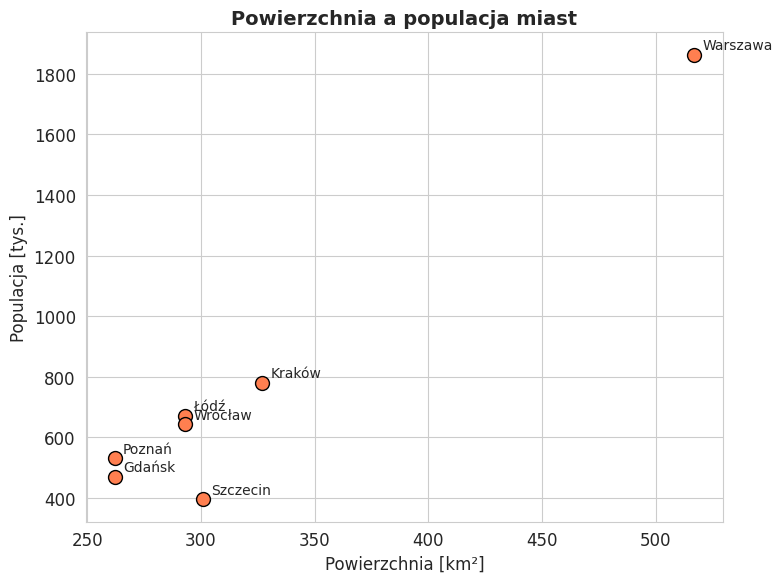

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(miasta["Powierzchnia_km2"], miasta["Populacja_tys"],
           s=100, color="coral", edgecolors="black")

# Podpisujemy każdy punkt nazwą miasta
for _, wiersz in miasta.iterrows():
    ax.annotate(wiersz["Miasto"],
                (wiersz["Powierzchnia_km2"], wiersz["Populacja_tys"]),
                textcoords="offset points", xytext=(6, 4), fontsize=10)

ax.set_title("Powierzchnia a populacja miast", fontsize=14, fontweight="bold")
ax.set_xlabel("Powierzchnia [km²]")
ax.set_ylabel("Populacja [tys.]")
plt.tight_layout()
plt.show()

### Metoda 2: pandas

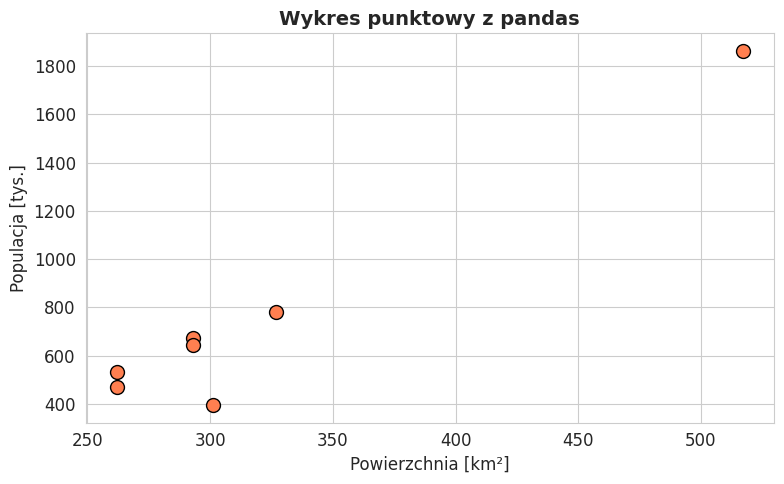

In [ ]:
miasta.plot.scatter(x="Powierzchnia_km2", y="Populacja_tys",
                    s=100, color="coral", edgecolors="black", figsize=(8, 5))
plt.title("Wykres punktowy z pandas", fontsize=14, fontweight="bold")
plt.xlabel("Powierzchnia [km²]")
plt.ylabel("Populacja [tys.]")
plt.tight_layout()
plt.show()

### Metoda 3: seaborn

Kolor (`hue`) i wielkość punktu (`size`) mogą przenosić kolejne zmienne – tu kategorię i gęstość zaludnienia.

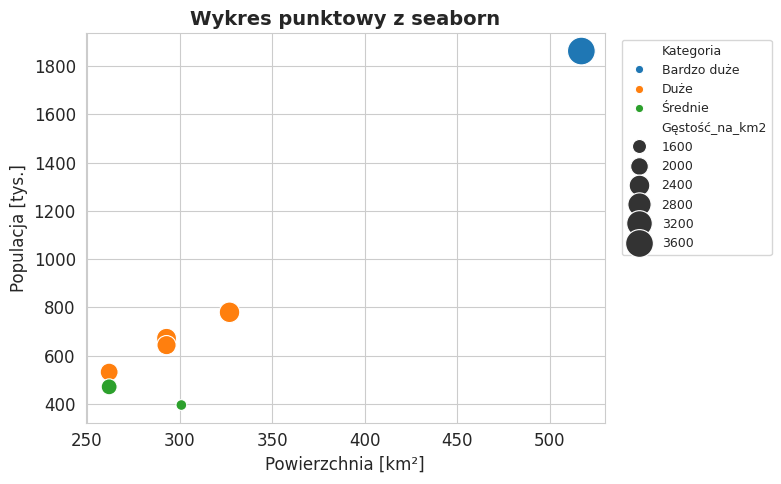

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=miasta, x="Powierzchnia_km2", y="Populacja_tys",
                hue="Kategoria", size="Gęstość_na_km2", sizes=(60, 400))

plt.title("Wykres punktowy z seaborn", fontsize=14, fontweight="bold")
plt.xlabel("Powierzchnia [km²]")
plt.ylabel("Populacja [tys.]")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

> **Myślenie eksploracyjne:** mamy tylko 7 punktów, a Warszawa odstaje w obu wymiarach. Czy bez niej zależność nadal byłaby widoczna? Z tak małej próby nie wyciągamy mocnych wniosków.

## CZĘŚĆ 9: WYKRES LINIOWY i FORMAT SZEROKI vs DŁUGI

**Pytanie:** jak zmienia się temperatura w ciągu roku w różnych miastach?

DataFrame `temperatura` jest w **formacie szerokim**: jeden wiersz = jedno miasto, a miesiące są *nazwami kolumn*.

In [ ]:
miesiace = ["Styczeń", "Kwiecień", "Lipiec", "Październik"]

# Indeksem są miasta, kolumnami – miesiące
temp_szeroka = temperatura.set_index("Miasto")[miesiace]
temp_szeroka

,Styczeń,Kwiecień,Lipiec,Październik
Miasto,,,,
Warszawa,-2,9,19,9
Kraków,-1,10,20,9
Gdańsk,0,8,17,10
Wrocław,-1,11,21,10
Poznań,-2,10,19,9
Łódź,-3,9,20,8


### Metoda 1: matplotlib – pętla po wierszach

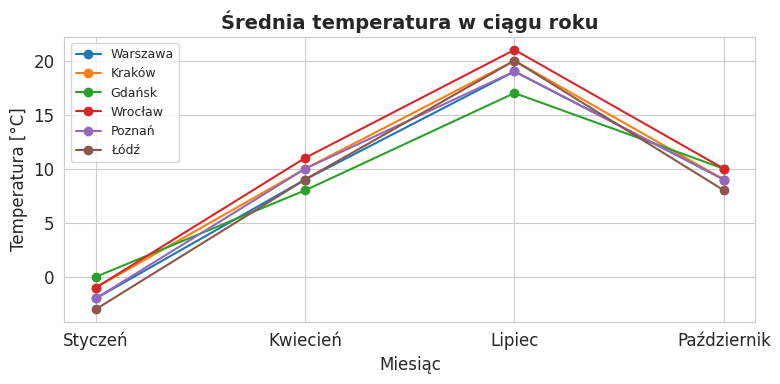

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for miasto, wiersz in temp_szeroka.iterrows():
    ax.plot(miesiace, wiersz.values, marker="o", label=miasto)

ax.set_title("Średnia temperatura w ciągu roku", fontsize=14, fontweight="bold")
ax.set_xlabel("Miesiąc")
ax.set_ylabel("Temperatura [°C]")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### Metoda 2: pandas – lubi format szeroki

`.plot()` rysuje **każdą kolumnę jako osobną linię**, a indeks trafia na oś X. Chcemy miesiące na osi X, więc transponujemy tabelę (`.T`).

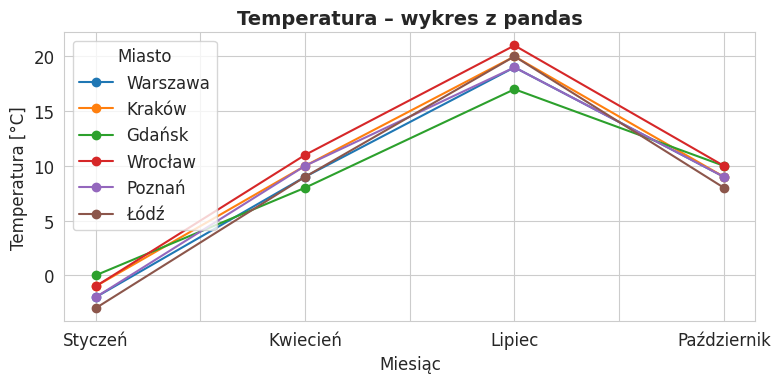

In [ ]:
temp_szeroka.T.plot(marker="o", figsize=(8, 4))

plt.title("Temperatura – wykres z pandas", fontsize=14, fontweight="bold")
plt.xlabel("Miesiąc")
plt.ylabel("Temperatura [°C]")
plt.tight_layout()
plt.show()

### Format długi: `pd.melt()`

Seaborn potrzebuje **formatu długiego**: jeden wiersz = jedna obserwacja (miasto, miesiąc, temperatura), a każda zmienna jest osobną kolumną. Dopiero wtedy „miesiąc” jest kolumną, którą możemy podpiąć pod oś X, a „miasto” – pod kolor (`hue`).

In [ ]:
temp_dluga = temperatura.melt(id_vars="Miasto",
                              value_vars=miesiace,
                              var_name="Miesiąc",
                              value_name="Temperatura")

print("Format szeroki:", temp_szeroka.shape)
print("Format długi:  ", temp_dluga.shape)
temp_dluga.head(8)

Format szeroki: (6, 4)
Format długi:   (24, 3)


,Miasto,Miesiąc,Temperatura
0,Warszawa,Styczeń,-2
1,Kraków,Styczeń,-1
2,Gdańsk,Styczeń,0
3,Wrocław,Styczeń,-1
4,Poznań,Styczeń,-2
5,Łódź,Styczeń,-3
6,Warszawa,Kwiecień,9
7,Kraków,Kwiecień,10


### Metoda 3: seaborn

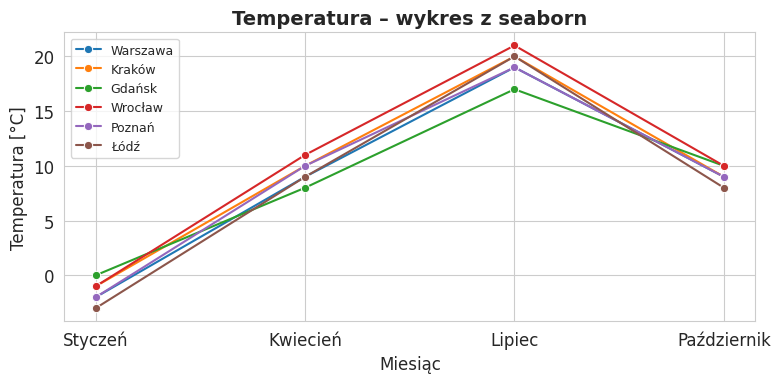

In [ ]:
plt.figure(figsize=(8, 4))
sns.lineplot(data=temp_dluga, x="Miesiąc", y="Temperatura",
             hue="Miasto", marker="o")

plt.title("Temperatura – wykres z seaborn", fontsize=14, fontweight="bold")
plt.ylabel("Temperatura [°C]")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

Z tych samych danych w formacie długim jedną linijką zmienimy typ wykresu – np. na słupki pogrupowane według miesiąca:

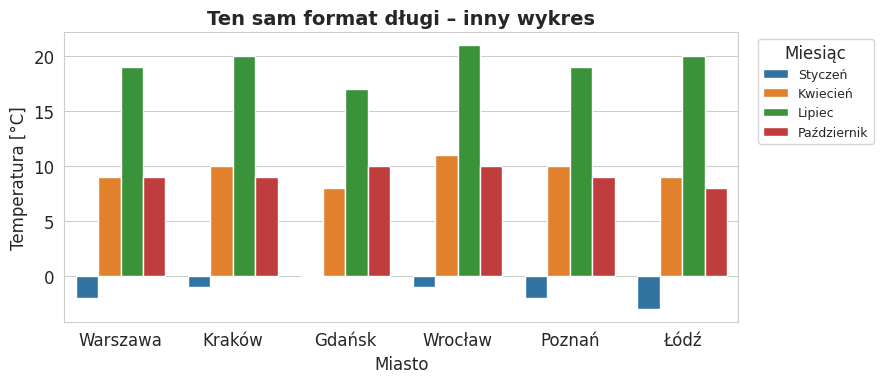

In [ ]:
plt.figure(figsize=(9, 4))
sns.barplot(data=temp_dluga, x="Miasto", y="Temperatura", hue="Miesiąc")
plt.title("Ten sam format długi – inny wykres", fontsize=14, fontweight="bold")
plt.ylabel("Temperatura [°C]")
plt.legend(title="Miesiąc", fontsize=9, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Z powrotem: `pivot()`

Operacją odwrotną do `melt()` jest `pivot()`. Uwaga: kolumny zostaną posortowane alfabetycznie – kolejność miesięcy przywracamy, wybierając je listą.

In [ ]:
temp_dluga.pivot(index="Miasto", columns="Miesiąc", values="Temperatura")[miesiace]

Miesiąc,Styczeń,Kwiecień,Lipiec,Październik
Miasto,,,,
Gdańsk,0,8,17,10
Kraków,-1,10,20,9
Poznań,-2,10,19,9
Warszawa,-2,9,19,9
Wrocław,-1,11,21,10
Łódź,-3,9,20,8


# **Zadania – część B**

Każdy wykres musi mieć tytuł, opisy osi (z jednostkami) i – jeśli jest więcej niż jedna seria – legendę.

## **Zadanie 7: Wykres liniowy i brakujące dane**

Liczba mieszkańców Warszawy i Łodzi w wybranych latach:

| Rok  | Warszawa  | Łódź      |
|------|-----------|-----------|
| 2002 | 1672000   | 789318    |
| 2011 | 1707000   | 728892    |
| 2015 | 1740000   | brak      |
| 2022 | 1795000   | 670642    |

a) Utwórz słownik z powyższymi danymi (użyj `None` dla brakującej wartości) i stwórz z niego DataFrame.

b) Zapisz DataFrame do pliku `populacja_miast.csv`, a następnie wczytaj go z powrotem.

c) Narysuj wykres liniowy zmian populacji obu miast w matplotlib – różne kolory i markery dla miast.

d) Narysuj ten sam wykres w seaborn (wskazówka: najpierw `melt`).

e) Co dzieje się z linią Łodzi w roku 2015? Czym różni się wynik, jeśli przed rysowaniem usuniesz wiersz z brakiem (`dropna()`)? Który wykres lepiej oddaje dane?

Wczytane dane:
    Rok  Warszawa      Łódź
0  2002   1672000  789318.0
1  2011   1707000  728892.0
2  2015   1740000       NaN
3  2022   1795000  670642.0


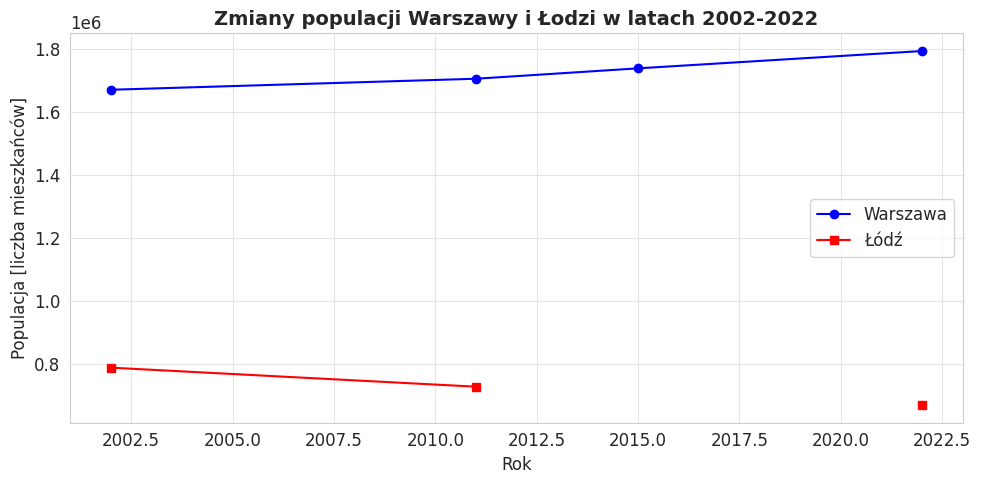

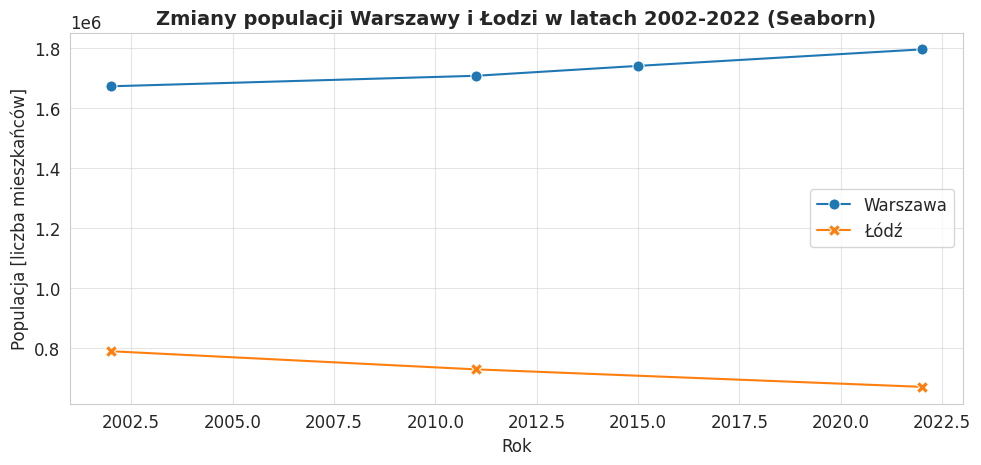

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data_populacja = {
    "Rok": [2002, 2011, 2015, 2022],
    "Warszawa": [1672000, 1707000, 1740000, 1795000],
    "Łódź": [789318, 728892, None, 670642]
}

df_populacja = pd.DataFrame(data_populacja)

df_populacja.to_csv('populacja_miast.csv', index=False)
df_populacja_odczyt = pd.read_csv('populacja_miast.csv')

print("Wczytane dane:")
print(df_populacja_odczyt)


plt.figure(figsize=(10, 5))

plt.plot(df_populacja_odczyt['Rok'], df_populacja_odczyt['Warszawa'],
         marker='o', color='blue', label='Warszawa')
plt.plot(df_populacja_odczyt['Rok'], df_populacja_odczyt['Łódź'],
         marker='s', color='red', label='Łódź')

plt.title('Zmiany populacji Warszawy i Łodzi w latach 2002-2022', fontsize=14, fontweight='bold')
plt.xlabel('Rok')
plt.ylabel('Populacja [liczba mieszkańców]')
plt.legend()
plt.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()


df_melt = df_populacja_odczyt.melt(
    id_vars=['Rok'],
    value_vars=['Warszawa', 'Łódź'],
    var_name='Miasto',
    value_name='Populacja'
)

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_melt, x='Rok', y='Populacja', hue='Miasto', style='Miasto',
             markers=True, dashes=False, markersize=8)

plt.title('Zmiany populacji Warszawy i Łodzi w latach 2002-2022 (Seaborn)', fontsize=14, fontweight='bold')
plt.xlabel('Rok')
plt.ylabel('Populacja [liczba mieszkańców]')
plt.legend()
plt.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

Co dzieje się z linią Łodzi w roku 2015 bez usuwania braków?

W Matplotlib linia automatycznie „prześwituje” / łączy punkt z 2011 bezpośrednio z punktem w 2022 roku, ignorując brak wartości w 2015 (tworzy się przerwa wrysowaniu lub linia przeskakuje nad brakującym rokiem).

Czym różni się wynik po użyciu dropna()?

Po użyciu dropna() wiersz dla 2015 roku jest usuwany całkowicie. W efekcie na wykresie linia Łodzi ma narysowany prosty odcinek łączący 2011 rok bezpośrednio z 2022 (oś X traktuje te lata jako następujące bezpośrednio po sobie, co fałszuje skalę czasu).

Który wykres lepiej oddaje dane?

Lepiej dane oddaje wykres bez usuwania wiersza (lub z jawnym zaznaczeniem NaN), ponieważ zachowuje poprawną oś czasu i odstępy między latami (2011 -> 2015 -> 2022), pokazując lukę analityczną, zamiast fałszować ciągłość historyczną.

## **Zadanie 8: Wykres punktowy z linią trendu**

a) Wygeneruj 100 losowych obserwacji:
   - `godziny_nauki` – liczby z przedziału od 0 do 10,
   - `ocena` – obliczona jako `50 + godziny_nauki * 5 + szum`, gdzie szum to losowe liczby od −10 do 10.

b) Stwórz z nich DataFrame.

c) Narysuj wykres punktowy zależności oceny od liczby godzin nauki.

d) Dodaj linię trendu (`sns.regplot`). Czy zależność jest wyraźna?

   Godziny_nauki       Ocena
0       3.745401   59.355590
1       9.507143  100.263924
2       7.319939   82.886817
3       5.986585   80.104338
4       1.560186   65.952262


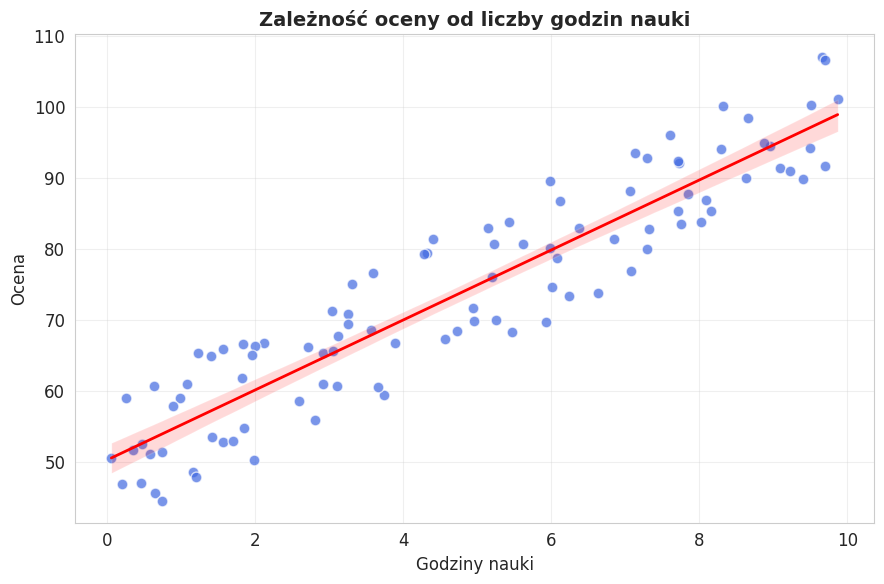

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

godziny_nauki = np.random.uniform(0, 10, 100)
szum = np.random.uniform(-10, 10, 100)
ocena = 50 + godziny_nauki * 5 + szum

df_wyniki = pd.DataFrame({
    'Godziny_nauki': godziny_nauki,
    'Ocena': ocena
})

print(df_wyniki.head())

plt.figure(figsize=(9, 6))

sns.regplot(
    data=df_wyniki,
    x='Godziny_nauki',
    y='Ocena',
    scatter_kws={'alpha': 0.7, 'color': 'royalblue', 'edgecolor': 'w', 's': 60},
    line_kws={'color': 'red', 'linewidth': 2}
)

plt.title('Zależność oceny od liczby godzin nauki', fontsize=14, fontweight='bold')
plt.xlabel('Godziny nauki')
plt.ylabel('Ocena')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Twoje rozwiązanie

## **Zadanie 9: Poziomy wykres słupkowy**

Przeciętne miesięczne wynagrodzenie w wybranych miastach (dane przykładowe):

| Miasto    | Wynagrodzenie [PLN] |
|-----------|---------------------|
| Warszawa  | 8500                |
| Kraków    | 7200                |
| Wrocław   | 7400                |
| Poznań    | 7100                |
| Gdańsk    | 6900                |
| Łódź      | 6300                |

a) Utwórz DataFrame z powyższymi danymi.

b) Narysuj **poziomy** wykres słupkowy (`barh` w matplotlib lub `sns.barplot(..., orient="h")`).

c) Posortuj miasta tak, żeby najwyższe wynagrodzenie było na górze.

d) Dodaj wartości na końcach słupków (wskazówka: `ax.bar_label(...)`).

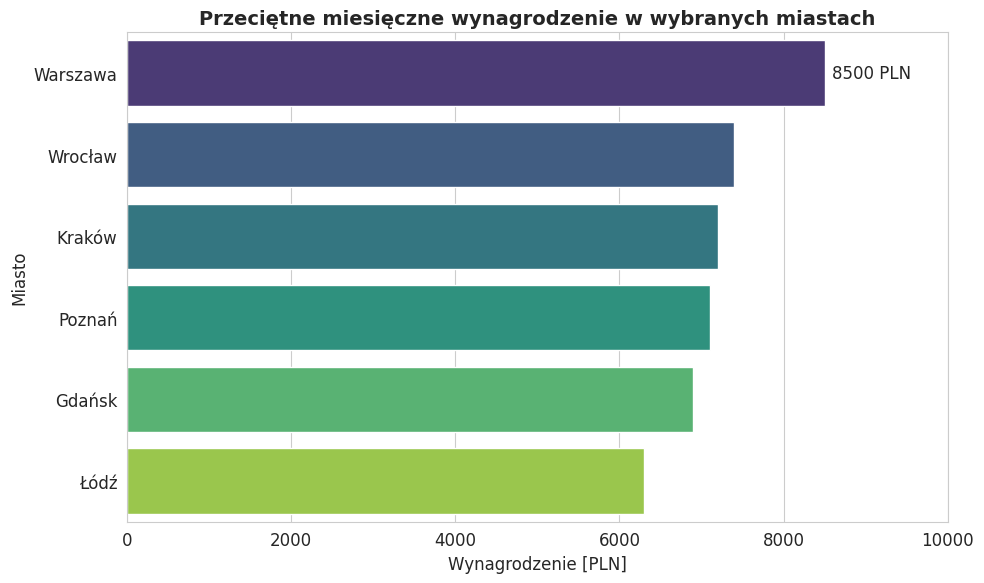

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data_wynagrodzenia = {
    'Miasto': ['Warszawa', 'Kraków', 'Wrocław', 'Poznań', 'Gdańsk', 'Łódź'],
    'Wynagrodzenie [PLN]': [8500, 7200, 7400, 7100, 6900, 6300]
}
df_wynagrodzenia = pd.DataFrame(data_wynagrodzenia)

df_posortowane = df_wynagrodzenia.sort_values(by='Wynagrodzenie [PLN]', ascending=False)

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=df_posortowane,
    x='Wynagrodzenie [PLN]',
    y='Miasto',
    orient='h',
    hue='Miasto',
    palette='viridis',
    legend=False
)

ax.bar_label(ax.containers[0], padding=5, fmt='%d PLN')

plt.title('Przeciętne miesięczne wynagrodzenie w wybranych miastach', fontsize=14, fontweight='bold')
plt.xlabel('Wynagrodzenie [PLN]')
plt.ylabel('Miasto')
plt.xlim(0, 10000)

plt.tight_layout()
plt.show()

## **Zadanie 10 (dodatkowe): Format długi w praktyce**

Wykorzystaj DataFrame `wyniki_egzaminy` z zadania zaawansowanego.

a) Przekształć go do formatu długiego: kolumny `Student`, `Kierunek`, `Przedmiot`, `Wynik` (wskazówka: `melt` z `id_vars=["Student", "Kierunek"]` i `value_vars` = trzy przedmioty).

b) Narysuj `sns.barplot` z przedmiotem na osi X, wynikiem na osi Y i kierunkiem jako `hue`.

c) Czy studenci danego kierunku osiągają najlepsze wyniki z „własnego” przedmiotu?

d) Dlaczego ten wykres trudno byłoby narysować z danych w formacie szerokim?

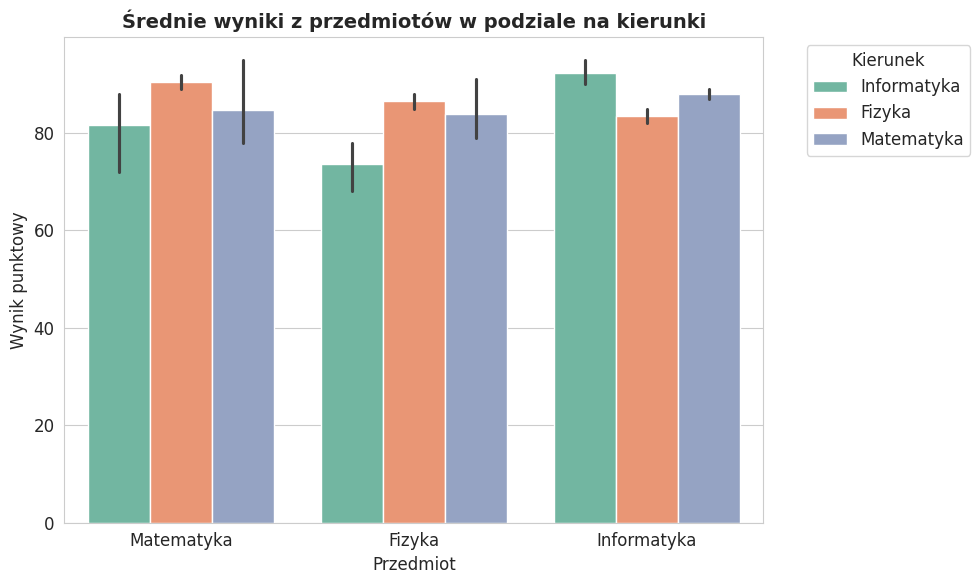

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

wyniki_dlugie = wyniki_egzaminy.melt(
    id_vars=["Student", "Kierunek"],
    value_vars=["Matematyka", "Fizyka", "Informatyka"],
    var_name="Przedmiot",
    value_name="Wynik"
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=wyniki_dlugie,
    x="Przedmiot",
    y="Wynik",
    hue="Kierunek",
    palette="Set2"
)

plt.title("Średnie wyniki z przedmiotów w podziale na kierunki", fontsize=14, fontweight='bold')
plt.xlabel("Przedmiot")
plt.ylabel("Wynik punktowy")
plt.legend(title="Kierunek", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

c) Czy studenci danego kierunku osiągają najlepsze wyniki z „własnego” przedmiotu?   
Nie zawsze wprost, ale zazwyczaj tak np. studenci Matematyki osiągają bardzo dobre wyniki, jednak wykres barplot pokazuje średnie lub rozkłady zagregowane; szczegółowa analiza zależy od konkretnego zestawu danych (w tym zbiorze np. informatycy świetnie radzą sobie z informatyką, ale fizycy lub matematycy również osiągają wysokie wyniki na styku dziedzin).

d) Dlaczego ten wykres trudno byłoby narysować z danych w formacie szerokim?

   Biblioteka Seaborn (oraz większość nowoczesnych narzędzi wizualizacyjnych opartych na grammar of graphics) oczekuje przypisania konkretnych kolumn DataFrame do konkretnych ról wizualnych (oś X to kategoria przedmiotu, oś Y to wartość liczbowa, hue to podział na grupy). W formacie szerokim przedmioty były nazwami oddzielnych kolumn, a wartości były rozproszone, co uniemożliwiało bezpośrednie przekazanie jednej kolumny jako osi X i grupowania ich parametrem hue bez uprzedniego przekształcenia (melt).